In [1]:
from pylablib.devices import Thorlabs
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

powermeter2 = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)


from mdt69x import Controller
controller = Controller("COM4")

In [34]:
controller.set_x_voltage(13)

1

In [36]:
laser.set(0.04)

In [ ]:
voltages = np.linspace(21, 22, 30)
poweroutx = []
powerouty = []
laser.set(0)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)

21.1
21.1
21.1
21.2
21.2
21.2
21.3
21.3
21.4
21.4
21.4
21.5
21.5
21.5
21.6
21.6
21.6
21.7
21.7
21.7
21.8
21.8
21.8
21.9
21.9
21.9
22.0
22.0
22.0
22.1
[0.012933665745333334, 0.016501436667999997, 0.006448840932133334, 0.009724918811533333, 0.0062468802744, 0.005181061935266668, 0.0059664081496, 0.007671753888, 0.005618612999333334, 0.007997116086199999, 0.008928336348333335, 0.016097554822000003, 0.008434682969266666, 0.006572250287326668, 0.004788368978726666, 0.008243966611333335, 0.008445911436666667, 0.005427880754000001, 0.00663957316264, 0.011968807987333336, 0.010016603460666663, 0.020338482722000003, 0.021135081038000006, 0.020618986704, 0.017455097936000002, 0.01831899526533333, 0.01765705036933334, 0.020237514264000004, 0.01720826302266667, 0.015289752012666667]
[-0.018391798176666665, -0.0275823422446, -0.03163169904, -0.044341553359999994, -0.04657822276, -0.04968415007333332, -0.04721426460666666, -0.04852869986666667, -0.04782909399533334, -0.044341554086666665, -0.0332111

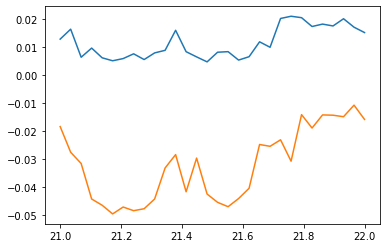

In [466]:
voltages = np.linspace(21, 22, 30)
poweroutx = []
powerouty = []
laser.set(0)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)

----- Forward (up) sweep -----
24.9
24.9
24.9
24.9
24.9
24.9
24.9
25.0
25.0
25.0
25.0
25.0
25.0
25.0
25.0
25.0
25.0
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.3
25.3
25.3
25.3
25.3
25.3
25.3
25.3
25.3
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.9
25.9
25.9
25.9
----- Backward (down) sweep -----
25.9
25.9
25.9
25.9
25.9
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.8
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.7
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.6
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.5
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.4
25.3
25.3
25.3
25.3
25.3
25.3
25.3
25.3
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.2
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.1
25.0
25.0
25.0


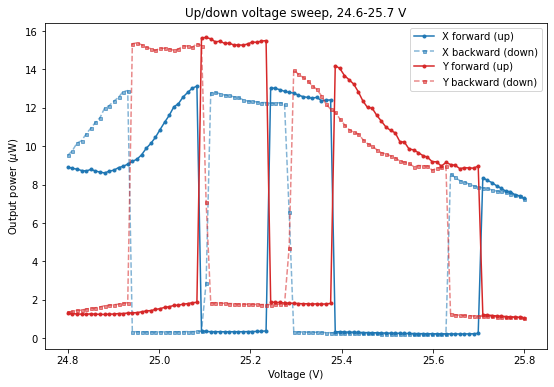

In [46]:
voltages = np.linspace(24.8, 25.8, 100)
laser.set(0.034)

def sweep(volt_points, direction_name):
    """沿给定电压序列扫描一遍，返回两个通道的强度数组"""
    outx, outy = [], []
    print(f'----- {direction_name} sweep -----')
    for x in volt_points:
        controller.set_x_voltage(x)
        time.sleep(0.1)
        print(controller.get_x_voltage())
        power_reading = []
        power_reading_y = []
        for k in range(1):
            power_reading.append(10**6 * powermeter.take_power_reading())
            power_reading_y.append(10**6 * powermeter2.take_power_reading())
        outx.append(np.mean(np.array(power_reading)))
        outy.append(np.mean(np.array(power_reading_y)))
    return np.asarray(outx), np.asarray(outy)

# 正向：升压扫描
poweroutx_fwd, powerouty_fwd = sweep(voltages, 'Forward (up)')
# 反向：沿相同的点降压扫回
poweroutx_bwd, powerouty_bwd = sweep(voltages[::-1], 'Backward (down)')
# 反向结果翻转回升序，使其与 voltages 一一对应
poweroutx_bwd, powerouty_bwd = poweroutx_bwd[::-1], powerouty_bwd[::-1]

laser.set(0)

print('voltages:',           voltages)
print('forward  X:', list(poweroutx_fwd))
print('forward  Y:', list(powerouty_fwd))
print('backward X:', list(poweroutx_bwd))
print('backward Y:', list(powerouty_bwd))

# ---------- 保存数据 ----------
import datetime
stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
np.savetxt(f'hysteresis_sweep_{stamp}.csv',
           np.column_stack([voltages,
                            poweroutx_fwd, powerouty_fwd,
                            poweroutx_bwd, powerouty_bwd]),
           delimiter=',',
           header='voltage_V,X_forward_uW,Y_forward_uW,X_backward_uW,Y_backward_uW',
           comments='')
print(f'Data saved to hysteresis_sweep_{stamp}.csv')

# ---------- 画图 ----------
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(voltages, poweroutx_fwd, '-o', ms=3, color='#1f77b4',
        label='X forward (up)')
ax.plot(voltages, poweroutx_bwd, '--s', ms=3, color='#1f77b4', alpha=0.55,
        label='X backward (down)')
ax.plot(voltages, powerouty_fwd, '-o', ms=3, color='#d62728',
        label='Y forward (up)')
ax.plot(voltages, powerouty_bwd, '--s', ms=3, color='#d62728', alpha=0.55,
        label='Y backward (down)')
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Output power ($\\mu$W)')
ax.set_title('Up/down voltage sweep, 24.6-25.7 V')
ax.legend()
plt.savefig(f'hysteresis_sweep_{stamp}.png', dpi=150, bbox_inches='tight')
plt.show()

19.1
19.1
19.1
19.2
19.2
19.2
19.2
19.3
19.3
19.3
19.3
19.3
19.4
19.4
19.4
19.4
19.4
19.5
19.5
19.5
19.5
19.5
19.6
19.6
19.6
19.6
19.6
19.6
19.7
19.7
19.7
19.7
19.8
19.8
19.8
19.8
19.8
19.9
19.9
19.9
19.9
19.9
20.0
20.0
20.0
20.0
20.0
20.0
20.1
20.1
[3.7723454619999996, 3.722117390666667, 3.6977126153333333, 3.6747257899999997, 3.6532004893333334, 3.6338171866666666, 3.6288384146666672, 3.611829712, 3.5941476653333337, 3.573379854, 3.562530204666667, 3.5549532939999993, 3.5532791866666664, 3.554113421333333, 3.558276239333333, 3.877965642666667, 7.902193950000002, 7.717050113999998, 7.602308898000001, 7.5000010213333335, 7.533014134666664, 7.547327095999999, 7.596172963333334, 7.696710781333334, 7.796781332666669, 7.861647586, 7.953330411333334, 3.5578595993333333, 3.5457095706666664, 3.541624997333334, 3.537282676, 3.534324879333333, 3.5467513659999996, 7.555966295333334, 7.540989736666668, 7.430928206, 7.390772832666666, 7.298739547333334, 7.2889754846666674, 7.310183658, 7.400158816

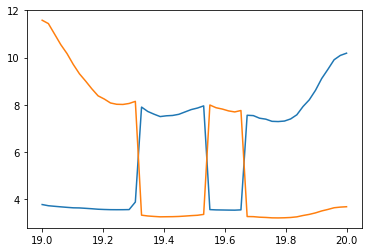

In [87]:
voltages = np.linspace(19.0,20.0,50)
poweroutx = []
powerouty = []
laser.set(0.031)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)

In [100]:
controller.set_x_voltage(18.5)

1

In [89]:
laser.set(0.030)

In [21]:
# Scan settings 2D scan
# change power . scan voltage

voltages = np.linspace(19,20,50)
laser_values = np.linspace(0.0311, 0.0355, 20)

poweroutx = []
powerouty = []

for laser_power in laser_values:

    print(f"\nLaser = {laser_power:.5f}")
    laser.set(laser_power)
    time.sleep(0.5)

    power_scan_x = []
    power_scan_y = []

    for v in voltages:

        controller.set_x_voltage(v)
        time.sleep(0.1)

        print(controller.get_x_voltage())

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

laser.set(0)

print("\n========== Voltage ==========")
print(voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)


Laser = 0.03110
22.1
22.1
22.1
22.1
22.1
22.1
22.2
22.2
22.2
22.2
22.2
22.2
22.3
22.3
22.3
22.3
22.3
22.3
22.3
22.3
22.4
22.4
22.4
22.4
22.4
22.4
22.4
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.6
22.6
22.6
22.6
22.6
22.6
22.7
22.7
22.7
22.7
22.7
22.7
22.7
22.8
22.8
22.8
22.8
22.8
22.8
22.8
22.9
22.9
22.9
22.9
22.9
22.9
22.9
22.9
23.0
23.0
23.0
23.0
23.0
23.0
23.0
23.0
23.1
23.1
23.1

Laser = 0.03133
22.1
22.1
22.1
22.1
22.1
22.2
22.2
22.2
22.2
22.2
22.2
22.2
22.3
22.3
22.3
22.3
22.3
22.3
22.3
22.4
22.4
22.4
22.4
22.4
22.4
22.4
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.6
22.6
22.6
22.6
22.6
22.6
22.6
22.6
22.7
22.7
22.7
22.7
22.7
22.7
22.8
22.8
22.8
22.8
22.8
22.8
22.8
22.9
22.9
22.9
22.9
22.9
22.9
22.9
23.0
23.0
23.0
23.0
23.0
23.0
23.0
23.0
23.0
23.1
23.1
23.1

Laser = 0.03156
22.1
22.1
22.1
22.1
22.1
22.2
22.2
22.2
22.2
22.2
22.2
22.2
22.2
22.3
22.3
22.3
22.3
22.3
22.3
22.3
22.4
22.4
22.4
22.4
22.4
22.4
22.4
22.5
22.5
22.5
22.5
22.5
22.5
22.5
22.6
22.6
22.6
22.6
22.6
22.6

In [13]:
# Scan settings 2D scan
# change voltage . scan power

# Reverse scan

voltages = np.linspace(22,23,25)
laser_values = np.linspace(0.0311, 0.0355, 25)

poweroutx = []
powerouty = []

for v in voltages:

    print(f"\nVoltage = {v:.5f}")
    controller.set_x_voltage(v)
    time.sleep(0.1)

    print(controller.get_x_voltage())

    power_scan_x = []
    power_scan_y = []

    for laser_power in laser_values:

        print(f"Laser = {laser_power:.5f}")
        laser.set(laser_power)
        time.sleep(0.5)

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

laser.set(0)

print("\n========== Voltage ==========")
print(voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)


Voltage = 22.00000
22.1
Laser = 0.03110


KeyboardInterrupt: 

In [ ]:
# Scan settings 2D scan
# change power . scan voltage

voltages = np.linspace(22,23,75)
laser_values = np.linspace(0.0311, 0.0355, 20)

poweroutx = []
powerouty = []

for laser_power in laser_values:

    print(f"\nLaser = {laser_power:.5f}")
    laser.set(laser_power)
    time.sleep(0.5)

    power_scan_x = []
    power_scan_y = []

    for v in voltages:

        controller.set_x_voltage(v)
        time.sleep(0.1)

        print(controller.get_x_voltage())

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

laser.set(0)

print("\n========== Voltage ==========")
print(voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)

In [101]:

# ---------------- scan settings ----------------
N_POINTS     = 300
V_START      = 15            # nominal window for the first row
V_STOP       = 25
laser_values = np.linspace(0.027, 0.055, 100)

# ---------------- drift-compensation settings ----------------
TH_SIGN      = 2.0             # uW; |A-B| above this defines the dominant channel
MAX_LAG      = 8               # samples; search window for row-to-row shift
MIN_SCORE    = 0.5             # accept a measured lag only above this match score
MAX_STEP_V   = 0.15            # V; clamp on the window move between two rows
V_HARD_MIN   = 0            # absolute piezo safety limits - ADJUST TO YOUR SETUP
V_HARD_MAX   = 45
EMA_ALPHA    = 0.5             # weight of the newest per-row drift in the EMA

step_v = (V_STOP - V_START) / (N_POINTS - 1)

def sign_pattern(a, b):
    """+1 where channel A dominates, -1 where B dominates, 0 ambiguous."""
    a = np.asarray(a); b = np.asarray(b)
    s = np.zeros(len(a), dtype=int)
    s[a - b >  TH_SIGN] =  1
    s[b - a >  TH_SIGN] = -1
    return s

def measure_lag(new, ref):
    """Best integer shift of `new` w.r.t. `ref` (units: samples).

    Positive lag  = pattern moved to HIGHER voltage/index.
    Returns (lag, score, valid). valid=False when the overlap carries no
    usable structure (no flip present) or the match is too poor.
    """
    best_lag, best_score = 0, -np.inf
    for lag in range(-MAX_LAG, MAX_LAG + 1):
        if lag >= 0:
            x, r = new[lag:], ref[:len(new) - lag]
        else:
            x, r = new[:lag], ref[-lag:]
        n = len(x)
        if n < 20:
            continue
        score = np.sum(x * r) / n
        if score > best_score or (score == best_score and abs(lag) < abs(best_lag)):
            best_lag, best_score = lag, score
    # degenerate: overlap contains only one polarization -> every lag ties
    has_flip = (np.any(new == 1) and np.any(new == -1))
    valid = has_flip and (best_score >= MIN_SCORE)
    return best_lag, best_score, valid

# ---------------- main scan ----------------
# Controller: window offset for the next row =
#     offset_now + R + ema_rate
#   R        = cumulative residual displacement of the pattern inside the
#              window (integral term; telescoping sum of measured lags, so it
#              is exactly "how far the pattern has crept from where it sat in
#              the reference row")
#   ema_rate = EMA of the TRUE drift rate (measured lag + correction already
#              applied that row), i.e. feed-forward that cancels the one-row
#              loop delay.
# Closed-loop simulation on steady / saturating / rate-changing drift shows
# all rows locked to the first row within ~1 sample after a 1-2 row transient.
poweroutx, poweroutty_rows, voltage_rows = [], [], []
sign_prev   = None
offset_v    = 0.0     # window offset applied to the CURRENT row
corr_prev   = 0.0     # correction applied between the previous row and this one
R_v         = 0.0     # integral term: cumulative residual (V)
ema_rate_v  = None    # feed-forward: smoothed true drift rate (V/row)
log_lines   = []

for row_idx, laser_power in enumerate(laser_values):

    print(f"\nLaser = {laser_power:.5f}   (window offset {offset_v:+.4f} V)")
    laser.set(laser_power)
    time.sleep(0.5)

    v_lo = V_START + offset_v
    v_hi = V_STOP  + offset_v
    # safety clamp on the absolute window
    v_lo = min(max(v_lo, V_HARD_MIN), V_HARD_MAX - (V_STOP - V_START))
    v_hi = v_lo + (V_STOP - V_START)
    voltages = np.linspace(v_lo, v_hi, N_POINTS)

    power_scan_x, power_scan_y = [], []
    for v in voltages:
        controller.set_x_voltage(v)
        time.sleep(0.1)
        print(controller.get_x_voltage())
        power_scan_x.append(1e6 * powermeter.take_power_reading())
        power_scan_y.append(1e6 * powermeter2.take_power_reading())

    poweroutx.append(power_scan_x)
    poweroutty_rows.append(power_scan_y)
    voltage_rows.append(voltages)

    # ---------- update the drift estimate for the NEXT row ----------
    sign_now = sign_pattern(power_scan_x, power_scan_y)
    if sign_prev is not None:
        lag, score, valid = measure_lag(sign_now, sign_prev)
        if valid:
            lag_v = lag * step_v                      # measured residual increment
            R_v += lag_v                              # integral term
            true_rate = lag_v + corr_prev             # what the cavity actually drifted
            ema_rate_v = (true_rate if ema_rate_v is None
                          else EMA_ALPHA * true_rate + (1 - EMA_ALPHA) * ema_rate_v)
        # invalid (no flip in overlap / poor match): leave R_v as is and
        # dead-reckon with the last known rate.
        rate = ema_rate_v if ema_rate_v is not None else 0.0
        correction = float(np.clip(R_v + rate, -MAX_STEP_V, MAX_STEP_V))
        offset_v += correction                        # applies from row 3 onward
        # NOTE: R_v needs no manual reduction. It is a telescoping sum of
        # measured lags, so the next row's lag (measured AFTER the window
        # moved) automatically brings R_v back toward zero; a clamped
        # correction leaves the remainder in R_v to be retried (anti-windup
        # by construction).
        corr_prev = correction
        log_lines.append(f"row {row_idx}: lag={lag:+d} px  score={score:.3f}  "
                         f"valid={valid}  rate={rate:+.4f} V/row  "
                         f"correction={correction:+.4f} V  offset_next={offset_v:+.4f} V")
        print(log_lines[-1])
    sign_prev = sign_now

laser.set(0)

# ---------------- output ----------------
print("\n========== Voltage rows (one axis per pump row) ==========")
for vr in voltage_rows:
    print(list(np.round(vr, 5)))

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(poweroutty_rows)

print("\n========== Drift log ==========")
for line in log_lines:
    print(line)



Laser = 0.02700   (window offset +0.0000 V)
15.1
15.1
15.2
15.2
15.2
15.3
15.3
15.4
15.4
15.4
15.4
15.5
15.5
15.6
15.6
15.6
15.7
15.7
15.7
15.8
15.8
15.8
15.9
15.9
15.9
16.0
16.0
16.0
16.1
16.1
16.1
16.2
16.2
16.2
16.3
16.3
16.3
16.4
16.4
16.4
16.5
16.5
16.5
16.5
16.6
16.6
16.6
16.7
16.7
16.8
16.8
16.8
16.9
16.9
16.9
16.9
17.0
17.0
17.0
17.1
17.1
17.2
17.2
17.2
17.3
17.3
17.3
17.4
17.4
17.4
17.5
17.5
17.5
17.6
17.6
17.6
17.7
17.7
17.7
17.8
17.8
17.8
17.9
17.9
17.9
18.0
18.0
18.0
18.1
18.1
18.1
18.2
18.2
18.2
18.3
18.3
18.3
18.4
18.4
18.4
18.5
18.5
18.5
18.6
18.6
18.6
18.6
18.7
18.7
18.8
18.8
18.8
18.9
18.9
18.9
19.0
19.0
19.0
19.1
19.1
19.1
19.1
19.2
19.2
19.3
19.3
19.3
19.4
19.4
19.4
19.5
19.5
19.5
19.6
19.6
19.6
19.7
19.7
19.7
19.8
19.8
19.8
19.9
19.9
19.9
20.0
20.0
20.0
20.1
20.1
20.1
20.2
20.2
20.2
20.3
20.3
20.3
20.4
20.4
20.4
20.5
20.5
20.5
20.6
20.6
20.6
20.7
20.7
20.7
20.8
20.8
20.8
20.9
20.9
20.9
21.0
21.0
21.0
21.1
21.1
21.1
21.2
21.2
21.2
21.3
21.3
21.3
21.4
21.4
21.4
21.5


KeyboardInterrupt: 

In [9]:
print(len(voltage_rows), len(poweroutx), len(poweroutty_rows))

NameError: name 'voltage_rows' is not defined

In [88]:
# ---------------- scan settings ----------------
N_POINTS     = 50
V_START      = 19            # nominal window for the first row  (sub-period!)
V_STOP       = 20
laser_values = np.linspace(0.031, 0.035, 50)

# ---------------- drift-compensation settings ----------------
BG_PCT       = 10              # percentile used as per-row per-channel background
MIN_CONTRAST = 1.0             # uW; (p95-p5) of corrected combined profile must
                               #     exceed this, else the row is "flat" (below
                               #     threshold) -> dead-reckoning
MIN_NCC      = 0.90            # accept a lag only if the combined NCC peak is
                               #     at least this (adjacent rows typically >0.97)
MAX_LAG_V    = 0.25            # V; +- search range for the row-to-row shift.
                               #     Sub-period windows have NO period ambiguity,
                               #     so a generous range is safe; it must exceed
                               #     the fastest expected drift per row (0.2 V/row
                               #     was seen at startup) but keep >=50% overlap.
MAX_STEP_V   = 0.15            # V; clamp on the window move between two rows
V_HARD_MIN   = 15.0            # absolute piezo safety limits - ADJUST TO YOUR SETUP
V_HARD_MAX   = 25.0
EMA_ALPHA    = 0.5             # weight of the newest per-row drift in the EMA

step_v  = (V_STOP - V_START) / (N_POINTS - 1)
MAX_LAG = min(int(round(MAX_LAG_V / step_v)), int(0.45 * N_POINTS))  # samples


def corrected_profiles(a, b):
    """Background-subtracted intensity profiles of both channels (uW)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return a - np.percentile(a, BG_PCT), b - np.percentile(b, BG_PCT)


def _ncc_at_lag(x, r, lag):
    """Pearson correlation of x shifted by `lag` against r, on the overlap.

    Positive lag = the new row's structure sits at HIGHER index than in the
    reference row (pattern moved toward higher voltage).
    """
    if lag >= 0:
        xs, rs = x[lag:], r[:len(x) - lag]
    else:
        xs, rs = x[:lag], r[-lag:]
    n = len(xs)
    if n < 20:
        return None
    xs = xs - xs.mean()
    rs = rs - rs.mean()
    sx, sr = xs.std(), rs.std()
    if sx < 1e-12 or sr < 1e-12:
        return None
    return float(np.dot(xs, rs) / (n * sx * sr))


def measure_lag_profile(a_now, b_now, a_ref, b_ref):
    """Sub-pixel shift of the current row's intensity contour vs the previous.

    Returns (lag_subpx, score, valid).
      lag_subpx : float, samples (positive = moved to higher voltage)
      score     : combined NCC at the (integer) peak
      valid     : False when the profiles carry no structure, the peak is too
                  poor, or the peak sits on the search boundary.
    """
    an, bn = corrected_profiles(a_now, b_now)
    ar, br = corrected_profiles(a_ref, b_ref)

    # structure check: is there anything to align on?
    contrast = max(np.percentile(an, 95) - np.percentile(an, 5),
                   np.percentile(bn, 95) - np.percentile(bn, 5))
    if contrast < MIN_CONTRAST:
        return 0.0, 0.0, False

    # channel weights ~ structure content of the current row
    wa, wb = an.std(), bn.std()
    wsum = wa + wb
    if wsum < 1e-12:
        return 0.0, 0.0, False
    wa, wb = wa / wsum, wb / wsum

    lags = np.arange(-MAX_LAG, MAX_LAG + 1)
    scores = np.full(len(lags), -np.inf)
    for i, lag in enumerate(lags):
        ca = _ncc_at_lag(an, ar, lag)
        cb = _ncc_at_lag(bn, br, lag)
        parts, wts = [], []
        if ca is not None:
            parts.append(ca); wts.append(wa)
        if cb is not None:
            parts.append(cb); wts.append(wb)
        if parts:
            scores[i] = float(np.average(parts, weights=wts))

    k = int(np.argmax(scores))
    peak = scores[k]
    on_boundary = (k == 0) or (k == len(lags) - 1)
    valid = (peak >= MIN_NCC) and not on_boundary

    # parabolic sub-pixel refinement around the integer peak
    lag_sub = float(lags[k])
    if valid:
        c_m, c_0, c_p = scores[k - 1], scores[k], scores[k + 1]
        denom = (c_m - 2.0 * c_0 + c_p)
        if np.isfinite(c_m) and np.isfinite(c_p) and abs(denom) > 1e-12:
            delta = 0.5 * (c_m - c_p) / denom
            if abs(delta) <= 1.0:          # sanity: refinement stays local
                lag_sub += delta
    return lag_sub, peak, valid


# ---------------- main scan ----------------
poweroutx, poweroutty_rows, voltage_rows = [], [], []
row_prev_a  = None
row_prev_b  = None
offset_v    = 0.0     # window offset applied to the CURRENT row
corr_prev   = 0.0     # correction applied between the previous row and this one
R_v         = 0.0     # integral term: cumulative residual (V)
ema_rate_v  = None    # feed-forward: smoothed true drift rate (V/row)
log_lines   = []

for row_idx, laser_power in enumerate(laser_values):

    print(f"\nLaser = {laser_power:.5f}   (window offset {offset_v:+.4f} V)")
    laser.set(laser_power)
    time.sleep(0.5)

    v_lo = V_START + offset_v
    v_hi = V_STOP  + offset_v
    # safety clamp on the absolute window
    v_lo = min(max(v_lo, V_HARD_MIN), V_HARD_MAX - (V_STOP - V_START))
    v_hi = v_lo + (V_STOP - V_START)
    voltages = np.linspace(v_lo, v_hi, N_POINTS)

    power_scan_x, power_scan_y = [], []
    for v in voltages:
        controller.set_x_voltage(v)
        time.sleep(0.1)
        print(controller.get_x_voltage())
        power_scan_x.append(1e6 * powermeter.take_power_reading())
        power_scan_y.append(1e6 * powermeter2.take_power_reading())

    poweroutx.append(power_scan_x)
    poweroutty_rows.append(power_scan_y)
    voltage_rows.append(voltages)

    # ---------- update the drift estimate for the NEXT row ----------
    if row_prev_a is not None:
        lag, score, valid = measure_lag_profile(power_scan_x, power_scan_y,
                                                row_prev_a, row_prev_b)
        if valid:
            lag_v = lag * step_v                      # measured residual increment
            R_v += lag_v                              # integral term
            true_rate = lag_v + corr_prev             # what the cavity actually drifted
            ema_rate_v = (true_rate if ema_rate_v is None
                          else EMA_ALPHA * true_rate + (1 - EMA_ALPHA) * ema_rate_v)
        # invalid (flat profile / poor or boundary NCC peak): keep R_v and
        # dead-reckon with the last known rate.
        rate = ema_rate_v if ema_rate_v is not None else 0.0
        correction = float(np.clip(R_v + rate, -MAX_STEP_V, MAX_STEP_V))
        offset_v += correction                        # applies from row 2 onward
        # NOTE: R_v needs no manual reduction - telescoping sum of measured
        # lags; a clamped correction leaves the remainder in R_v to be
        # retried next row (anti-windup by construction).
        corr_prev = correction
        log_lines.append(f"row {row_idx}: lag={lag:+.2f} px  score={score:.3f}  "
                         f"valid={valid}  rate={rate:+.4f} V/row  "
                         f"correction={correction:+.4f} V  offset_next={offset_v:+.4f} V")
        print(log_lines[-1])
    row_prev_a = power_scan_x
    row_prev_b = power_scan_y

laser.set(0)

# ---------------- output ----------------
print("\n========== Voltage rows (one axis per pump row) ==========")
for vr in voltage_rows:
    print(list(np.round(vr, 5)))

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(poweroutty_rows)

print("\n========== Drift log ==========")
for line in log_lines:
    print(line)


Laser = 0.03100   (window offset +0.0000 V)
19.1
19.1
19.1
19.2
19.2
19.2
19.2
19.3
19.3
19.3
19.3
19.3
19.4
19.4
19.4
19.4
19.4
19.5
19.5
19.5
19.5
19.5
19.6
19.6
19.6
19.6
19.6
19.7
19.7
19.7
19.7
19.7
19.8
19.8
19.8
19.8
19.8
19.9
19.9
19.9
19.9
19.9
20.0
20.0
20.0
20.0
20.0
20.0
20.1
20.1

Laser = 0.03108   (window offset +0.0000 V)
19.1
19.1
19.1
19.2
19.2
19.2
19.2
19.2
19.3
19.3
19.3
19.3
19.3
19.4
19.4
19.4
19.4
19.5
19.5
19.5
19.5
19.5
19.6
19.6
19.6
19.6
19.6
19.7
19.7
19.7
19.7
19.7
19.8
19.8
19.8
19.8
19.8
19.8
19.9
19.9
19.9
19.9
20.0
20.0
20.0
20.0
20.0
20.1
20.1
20.1
row 1: lag=-1.95 px  score=0.952  valid=True  rate=-0.0399 V/row  correction=-0.0797 V  offset_next=-0.0797 V

Laser = 0.03116   (window offset -0.0797 V)
19.0
19.0
19.1
19.1
19.1
19.1
19.1
19.2
19.2
19.2
19.2
19.2
19.3
19.3
19.3
19.3
19.4
19.4
19.4
19.4
19.4
19.5
19.5
19.5
19.5
19.5
19.6
19.6
19.6
19.6
19.6
19.6
19.7
19.7
19.7
19.7
19.8
19.8
19.8
19.8
19.8
19.9
19.9
19.9
19.9
19.9
20.0
20.0
20.0
20.0
row 2

In [26]:
# Scan settings 2D scan
# change power . scan voltage

voltages = np.linspace(23,30,100)
laser_values = np.linspace(0.0275,0.0255,30)

poweroutx = []
powerouty = []

for laser_power in laser_values:

    print(f"\nLaser = {laser_power:.5f}")
    laser.set(laser_power)
    time.sleep(0.5)

    power_scan_x = []
    power_scan_y = []

    for v in voltages:

        controller.set_x_voltage(v)
        time.sleep(0.1)

        print(controller.get_x_voltage())

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

laser.set(0)

print("\n========== Voltage ==========")
print(voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)


Laser = 0.02750
23.1
23.2
23.2
23.3
23.4
23.4
23.5
23.6
23.7
23.7
23.8
23.9
23.9
24.0
24.1
24.1
24.2
24.3
24.4
24.4
24.5
24.6
24.6
24.7
24.8
24.9
24.9
25.0
25.1
25.1
25.2
25.3
25.3
25.4
25.5
25.6
25.6
25.7
25.8
25.8
25.9
26.0
26.1
26.1
26.2
26.3
26.3
26.4
26.5
26.5
26.6
26.7
26.8
26.8
26.9
27.0
27.0
27.1
27.2
27.3
27.3
27.4
27.5
27.5
27.6
27.7
27.8
27.8
27.9
28.0
28.0
28.1
28.2
28.2
28.3
28.4
28.5
28.5
28.6
28.7
28.7
28.8
28.9
29.0
29.0
29.1
29.2
29.2
29.3
29.4
29.4
29.5
29.6
29.6
29.7
29.8
29.9
30.0
30.0
30.1

Laser = 0.02743
23.1
23.2
23.2
23.3
23.4
23.4
23.5
23.6
23.7
23.7
23.8
23.9
23.9
24.0
24.1
24.1
24.2
24.3
24.4
24.4
24.5
24.6
24.6
24.7
24.8
24.9
24.9
25.0
25.1
25.1
25.2
25.3
25.3
25.4
25.5
25.6
25.6
25.7
25.8
25.8
25.9
26.0
26.1
26.1
26.2
26.3
26.3
26.4
26.5
26.5
26.6
26.7
26.8
26.8
26.9
27.0
27.0
27.1
27.2
27.3
27.3
27.4
27.5
27.5
27.6
27.7
27.8
27.8
27.9
28.0
28.0
28.1
28.2
28.2
28.3
28.4
28.5
28.5
28.6
28.7
28.7
28.8
28.9
29.0
29.0
29.1
29.2
29.2
29.3
29.4
29.4
29.5
29.6
2

In [39]:
import os
import datetime

# ---------- 实时保存设置 ----------
save_dir = r"D:\Data\2026\202608"
os.makedirs(save_dir, exist_ok=True)   # 路径不存在则自动创建
stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
data_file = os.path.join(save_dir, f"2Dscan_{stamp}.txt")

# ---------- 扫描方向开关 ----------
# True  : 每个泵浦功率下, 电压先正着扫一遍(35→0.1), 再反着扫一遍(0.1→35)
# False : 只正着扫一遍 (与原来行为一致)
bidirectional = False

# Scan settings 2D scan
# change power, scan voltage
voltages = np.linspace(7, 30, 1200)
laser_values = np.linspace(0.037, 0.075, 40)





# 根据开关生成实际扫描用的电压序列
if bidirectional:
    scan_voltages = np.concatenate((voltages, voltages[::-1]))
else:
    scan_voltages = voltages

# 先把扫描参数写进文件头，之后每完成一条电压扫描就追加一行
with open(data_file, 'w') as f:
    f.write(f"# 2D scan started {stamp}\n")
    f.write(f"# Bidirectional scan: {bidirectional}"
            + (" (each block = forward 35->0.1 then backward 0.1->35)\n"
               if bidirectional else " (forward only)\n"))
    f.write("# Format: one block per laser power; "
            "columns = voltage_V, PM1_uW, PM2_uW\n")
    f.write("\n========== Voltage ==========\n")
    f.write(np.array2string(scan_voltages, threshold=np.inf) + "\n")
    f.write("\n========== Laser values ==========\n")
    f.write(np.array2string(laser_values, threshold=np.inf) + "\n")
    f.write("\n========== Data blocks ==========\n")
print(f"Saving to: {data_file}")

poweroutx = []
powerouty = []

for laser_power in laser_values:

    print(f"\nLaser = {laser_power:.5f}")
    laser.set(laser_power)
    time.sleep(0.5)

    power_scan_x = []
    power_scan_y = []

    for v in scan_voltages:

        controller.set_x_voltage(v)
        time.sleep(0.1)

        print(controller.get_x_voltage())

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

    # ---- 每完成一个泵浦功率的整条电压扫描, 立即追加保存 ----
    with open(data_file, 'a') as f:
        f.write(f"\n# ---- Laser = {laser_power:.6f} W ----\n")
        for v, px, py in zip(scan_voltages, power_scan_x, power_scan_y):
            f.write(f"{v:.6f}\t{px:.8f}\t{py:.8f}\n")
        f.flush()
        os.fsync(f.fileno())   # 强制写入磁盘, 防止断电/崩溃丢缓存

laser.set(0)

# ---- 结尾再存一份与原打印格式一致的完整汇总, 方便直接复制解析 ----
with open(data_file, 'a') as f:
    f.write("\n========== Power meter 1 ==========\n")
    f.write(str(poweroutx) + "\n")
    f.write("\n========== Power meter 2 ==========\n")
    f.write(str(powerouty) + "\n")

print("\n========== Voltage ==========")
print(scan_voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)

print(f"\nAll data saved to: {data_file}")

Saving to: D:\Data\2026\202608\2Dscan_20260829_201941.txt

Laser = 0.03700
7.1
7.1
7.2
7.2
7.2
7.2
7.2
7.2
7.3
7.3
7.3
7.3
7.3
7.3
7.4
7.4
7.4
7.4
7.5
7.5
7.5
7.5
7.6
7.6
7.6
7.6
7.6
7.6
7.6
7.7
7.7
7.7
7.7
7.7
7.8
7.8
7.8
7.8
7.8
7.9
7.9
7.9
7.9
7.9
7.9
8.0
8.0
8.0
8.0
8.1
8.1
8.1
8.1
8.1
8.1
8.2
8.2
8.2
8.2
8.2
8.3
8.3
8.3
8.3
8.3
8.3
8.4
8.4
8.4
8.4
8.5
8.5
8.5
8.5
8.5
8.6
8.6
8.6
8.6
8.6
8.6
8.7
8.7
8.7
8.7
8.7
8.8
8.8
8.8
8.8
8.8
8.9
8.9
8.9
8.9
8.9
8.9
9.0
9.0
9.0
9.0
9.0
9.1
9.1
9.1
9.1
9.1
9.1
9.2
9.2
9.2
9.2
9.3
9.3
9.3
9.3
9.3
9.4
9.4
9.4
9.4
9.4
9.4
9.4
9.5
9.5
9.5
9.5
9.5
9.6
9.6
9.6
9.6
9.7
9.7
9.7
9.7
9.7
9.7
9.8
9.8
9.8
9.8
9.9
9.9
9.9
9.9
9.9
9.9
9.9
10.0
10.0
10.0
10.0
10.1
10.1
10.1
10.1
10.1
10.2
10.2
10.2
10.2
10.2
10.2
10.3
10.3
10.3
10.3
10.3
10.4
10.4
10.4
10.4
10.4
10.5
10.5
10.5
10.5
10.5
10.6
10.6
10.6
10.6
10.6
10.6
10.7
10.7
10.7
10.7
10.8
10.8
10.8
10.8
10.8
10.8
10.9
10.9
10.9
10.9
10.9
11.0
11.0
11.0
11.0
11.0
11.1
11.1
11.1
11.1
11.1
11.1
11.2
11.2
11.2
